# Reading data from [NESO's](https://www.neso.energy/) API

The same steps as `api_demo.py`, but broken into cells you can run one at a time.

Press `Shift` + `Enter` to run a cell and move to the next one.

1. Fetch data from the API
2. Look at the raw response
3. Load it into a table (a pandas DataFrame)
4. Plot a chart


## 1. Fetch data from the API

We ask for 100 rows (`limit=100`) from one dataset (identified by `resource_id`).

- **`httpx`** is the library that fetches things over the internet.
- **`RESOURCE_ID`** identifies the dataset. Every dataset on the [NESO Data Portal](https://www.neso.energy/data-portal/api-guidance) has an "API" button that shows its id.
- **`params`** is a dict of query-string arguments: `httpx` turns it into `?resource_id=...&limit=100` and sticks it on the end of the URL.


In [243]:
import httpx  # fetches things over the internet
import pandas as pd  # tables of data
import matplotlib.pyplot as plt  # charts

API_URL = "https://api.neso.energy/api/3/action/datastore_search"
RESOURCE_ID = "8ba48f26-d73e-4094-a90d-ba075eb739c1"

response = httpx.get(API_URL, params={"resource_id": RESOURCE_ID, "limit": 100})
payload = response.json()  # the response, converted into a Python dictionary

payload.keys()


dict_keys(['help', 'success', 'result'])

## 2. Print the data

The actual rows are nested under `result` -> `records`. Let's look at the first one.

In [252]:
records = payload["result"]["records"]
print(f"Fetched {len(records)} records")
records[0]

Fetched 100 records


{'_id': 1,
 'auctionID': 2843,
 'registeredAuctionParticipant': 'EDF ENERGY CUSTOMERS LIMITED',
 'auctionUnit': 'PINFB-2',
 'basketID': 28177541,
 'serviceType': 'Response',
 'deliveryStart': '2026-09-16T18:00:00',
 'deliveryEnd': '2026-09-16T22:00:00',
 'orderID': 70177325,
 'orderType': 'CHILD',
 'auctionProduct': 'DML',
 'productID': 4,
 'quantity': 1,
 'priceLimit': 23.37,
 'loopedBasketID': None,
 'orderEntryTime': '2026-09-15T11:53:40',
 'acceptanceRatio': 0.0,
 'status': 'REJECTED',
 'executedQuantity': 0,
 'clearingPrice': 16.37,
 'reasonRejected': '21',
 'flexibleGroupID': None,
 'minimumConsecutiveWindows': None}

## 3. Load into a DataFrame and inspect

A `DataFrame` is a table, like a spreadsheet, much easier to explore than a raw list of dictionaries.


In [299]:
df = pd.DataFrame(records)
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 100 rows, 23 columns


,_id,auctionID,registeredAuctionParticipant,auctionUnit,basketID,serviceType,deliveryStart,deliveryEnd,orderID,orderType,...,priceLimit,loopedBasketID,orderEntryTime,acceptanceRatio,status,executedQuantity,clearingPrice,reasonRejected,flexibleGroupID,minimumConsecutiveWindows
0,1,2843,EDF ENERGY CUSTOMERS LIMITED,PINFB-2,28177541,Response,2026-09-16T18:00:00,2026-09-16T22:00:00,70177325,CHILD,...,23.37,NaN,2026-09-15T11:53:40,0.0,REJECTED,0,16.37,21,None,None
1,2,2843,EDF ENERGY CUSTOMERS LIMITED,KILSB-1,28177952,Response,2026-09-16T06:00:00,2026-09-16T10:00:00,70180027,CHILD,...,-19.99,NaN,2026-09-15T11:57:05,0.0,REJECTED,0,-17.50,22,None,None
2,3,2843,EDF ENERGY CUSTOMERS LIMITED,BLHLB-3,28177813,Response,2026-09-16T18:00:00,2026-09-16T22:00:00,70178931,CHILD,...,-14.36,NaN,2026-09-15T11:55:48,0.0,REJECTED,0,-13.00,22,None,None
3,4,2843,TESLA MOTORS LIMITED,THMRB-1,28148750,Response,2026-09-15T22:00:00,2026-09-16T02:00:00,70103263,CHILD,...,-17.71,NaN,2026-09-15T11:08:11,1.0,EXECUTED,5,-16.00,NaN,None,None
4,5,2843,EDF ENERGY CUSTOMERS LIMITED,COVNB-1,28177689,Response,2026-09-16T10:00:00,2026-09-16T14:00:00,70178034,CHILD,...,-19.99,NaN,2026-09-15T11:54:49,0.0,REJECTED,0,-13.82,22,None,None


In [300]:
# What columns do we have, and what type is each one?
df.dtypes

_id                               int64
auctionID                         int64
registeredAuctionParticipant        str
auctionUnit                         str
basketID                          int64
serviceType                         str
deliveryStart                       str
deliveryEnd                         str
orderID                           int64
orderType                           str
auctionProduct                      str
productID                         int64
quantity                          int64
priceLimit                      float64
loopedBasketID                  float64
orderEntryTime                      str
acceptanceRatio                 float64
status                              str
executedQuantity                  int64
clearingPrice                   float64
reasonRejected                      str
flexibleGroupID                  object
minimumConsecutiveWindows        object
dtype: object

In [301]:
# Quick numeric summary (count, mean, min, max, etc.) for numeric columns
df.describe()

,_id,auctionID,basketID,orderID,productID,quantity,priceLimit,loopedBasketID,acceptanceRatio,executedQuantity,clearingPrice
count,100.000000,100.0,1.000000e+02,1.000000e+02,100.000000,100.000000,100.000000,1.900000e+01,100.00000,100.000000,100.000000
mean,50.500000,2843.0,2.816641e+07,7.015142e+07,3.990000,8.280000,-9.953200,2.794199e+06,0.15000,1.370000,-14.074900
std,29.011492,0.0,1.693181e+04,3.742500e+04,2.883233,9.741176,11.784256,4.551944e+03,0.35887,4.464574,3.873666
min,1.000000,2843.0,2.814521e+07,7.009746e+07,1.000000,0.000000,-20.000000,2.791022e+06,0.00000,0.000000,-17.500000
25%,25.750000,2843.0,2.814920e+07,7.010722e+07,2.000000,2.000000,-19.040000,2.791298e+06,0.00000,0.000000,-16.000000
50%,50.500000,2843.0,2.817749e+07,7.017700e+07,3.000000,5.000000,-15.920000,2.791307e+06,0.00000,0.000000,-13.820000
75%,75.250000,2843.0,2.817795e+07,7.017998e+07,6.000000,9.250000,-0.505000,2.798992e+06,0.00000,0.000000,-13.000000
max,100.000000,2843.0,2.819874e+07,7.020766e+07,11.000000,60.000000,28.250000,2.801476e+06,1.00000,36.000000,16.370000


## 4. Plot a chart

Count how many orders were executed vs rejected, then draw it as a bar chart.


In [302]:
status_counts = df["status"].value_counts()
status_counts

status
REJECTED    85
EXECUTED    15
Name: count, dtype: int64

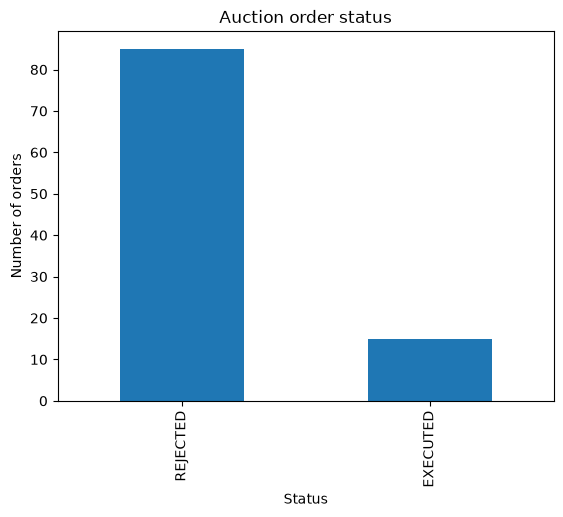

In [303]:
status_counts.plot(kind="bar", title="Auction order status")
plt.xlabel("Status")
plt.ylabel("Number of orders")
plt.show()

### Try it yourself

- Plot `clearingPrice` as a histogram to see the distribution of prices.
- Group by `auctionProduct` and compare average `quantity`.
- Change `limit=100` to a bigger number and see how the results change.

Below I have tried myself 15 September 2026:

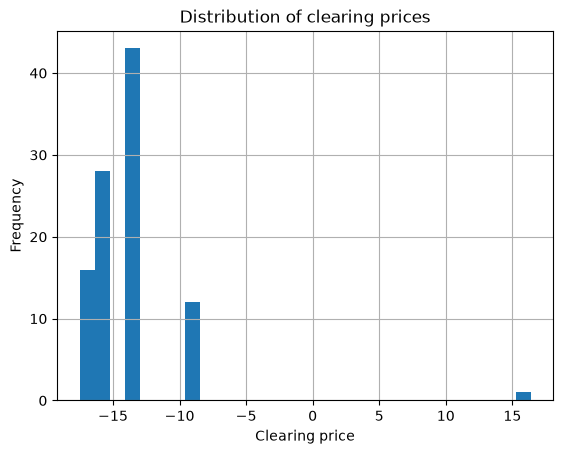

In [304]:
clearingPrice_counts = df["clearingPrice"].hist(bins=30)
plt.title("Distribution of clearing prices")
plt.xlabel("Clearing price")
plt.ylabel("Frequency")
plt.show()

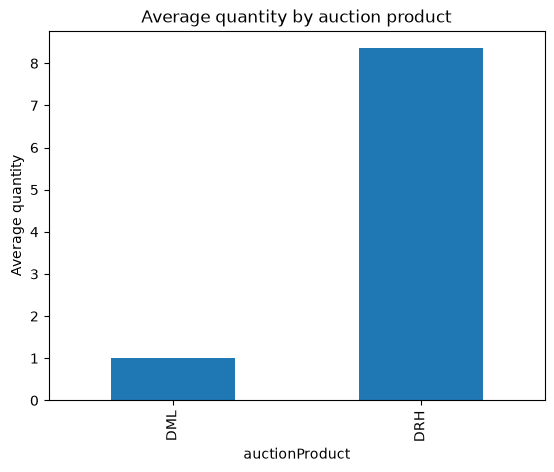

In [305]:
df.groupby("auctionProduct")["quantity"].mean().plot(kind="bar")
plt.title("Average quantity by auction product")
plt.ylabel("Average quantity")
plt.show()